# Importations alimentaires des Comores

Notebook du projet FAOSTAT. Les données brutes sont conservées sans modification.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:,.2f}".format)
sns.set_theme(style="whitegrid")

ROOT_DIR = Path.cwd()
if ROOT_DIR.name == "notebooks":
    ROOT_DIR = ROOT_DIR.parent
RAW_DIR = ROOT_DIR / "data" / "raw"
PROCESSED_DIR = ROOT_DIR / "data" / "processed"
FIGURES_DIR = ROOT_DIR / "figures"
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

## 1. Chargement

In [2]:
FILE = PROCESSED_DIR / "imports_comoros_processed.csv"
if not FILE.exists(): raise FileNotFoundError("Exécute le notebook 01.")
data = pd.read_csv(FILE)

## 2. Statistiques descriptives et distributions

,count,mean,std,min,25%,50%,75%,max
Quantity (t),"8,079.00",210.16,"2,248.22",0.00,0.25,3.00,28.00,"57,374.46"
Value (1000 USD),"8,162.00",116.54,"1,020.28",0.00,0.00,3.00,27.00,"28,728.00"


,0.05,0.25,0.50,0.75,0.95
Quantity (t),0.00,0.25,3.00,28.00,354.86
Value (1000 USD),0.00,0.00,3.00,27.00,309.00


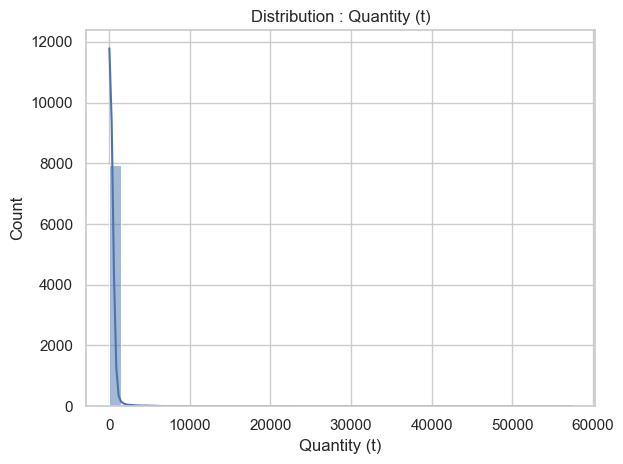

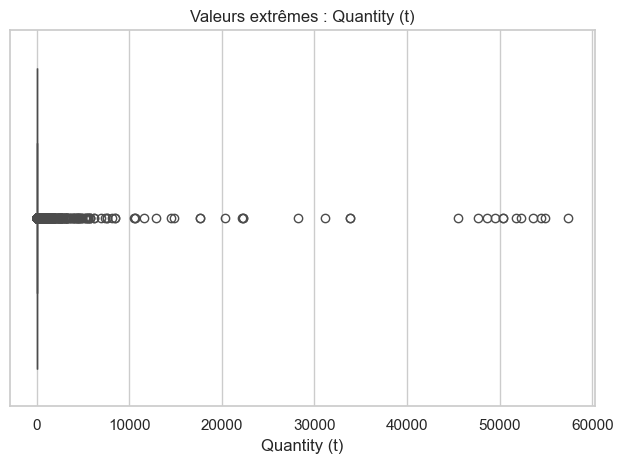

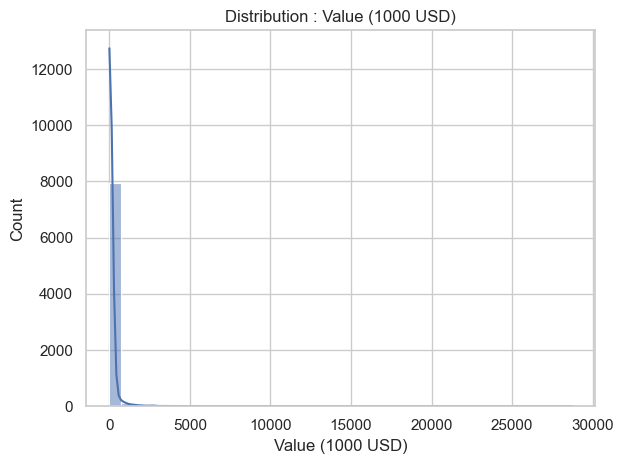

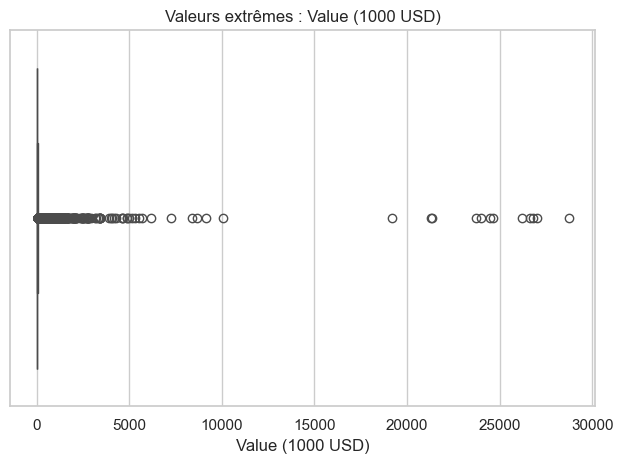

In [3]:
cols = ["Quantity (t)", "Value (1000 USD)"]
display(data[cols].describe().T)
display(data[cols].quantile([.05,.25,.5,.75,.95]).T)
for col in cols:
    sns.histplot(data[col].dropna(), bins=40, kde=True)
    plt.title(f"Distribution : {col}"); plt.tight_layout(); plt.show()
    sns.boxplot(x=data[col].dropna())
    plt.title(f"Valeurs extrêmes : {col}"); plt.tight_layout(); plt.show()

## 3. Corrélations

,Quantity (t),Value (1000 USD)
Quantity (t),1.00,0.95
Value (1000 USD),0.95,1.00


,Quantity (t),Value (1000 USD)
Quantity (t),1.00,0.91
Value (1000 USD),0.91,1.00


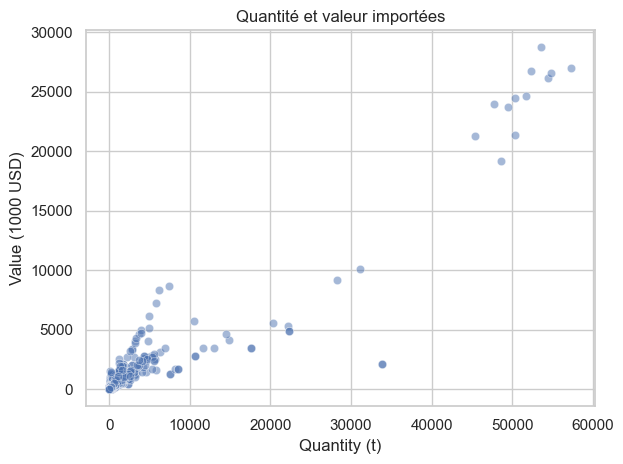

In [4]:
paired = data[cols].dropna()
display(paired.corr(method="pearson"))
display(paired.corr(method="spearman"))
sns.scatterplot(data=paired, x=cols[0], y=cols[1], alpha=.5)
plt.title("Quantité et valeur importées"); plt.tight_layout(); plt.show()

## 4. Analyse produit-année et valeur unitaire

In [5]:
py = data.groupby(["Item Code (CPC)", "Item", "Year"], as_index=False).agg(
    quantity_t=("Quantity (t)", "sum"),
    value_1000_usd=("Value (1000 USD)", "sum")
)
py = py[(py["quantity_t"] > 0) & py["value_1000_usd"].notna()].copy()
py["unit_value_usd_t"] = py["value_1000_usd"] * 1000 / py["quantity_t"]
display(py.sort_values("unit_value_usd_t", ascending=False).head(20))

,Item Code (CPC),Item,Year,quantity_t,value_1000_usd,unit_value_usd_t
356,01443,Rape or colza seed,2021,0.08,5.00,"62,500.00"
721,02192.01,Other rodents,2018,0.10,4.00,"40,000.00"
981,21183,"Other meat and edible meat offal, salted, in b...",2020,0.03,1.00,"33,333.33"
513,01658,"Vanilla, raw",1999,5.00,120.00,"24,000.00"
331,0141,Soya beans,2018,0.90,21.00,"23,333.33"
716,02151,Chickens,2021,0.59,13.00,"22,033.90"
2243,39120.04,Bran of maize,2018,0.05,1.00,"20,000.00"
351,0143,Cotton seed,2020,0.80,16.00,"20,000.00"
350,0143,Cotton seed,2019,0.21,4.00,"19,047.62"
1972,23912.02,Coffee extracts,1996,2.00,38.00,"19,000.00"


## 5. Test exploratoire entre périodes

Le test de Mann–Whitney compare les distributions des lignes disponibles. Les observations par pays et produit ne sont pas nécessairement indépendantes : le résultat reste descriptif et ne suffit pas à établir une conclusion causale.

In [6]:
from scipy.stats import mannwhitneyu
data["period"] = np.select(
    [data["Year"].between(1995,2002), data["Year"].between(2016,2021)],
    ["1995-2002", "2016-2021"], default="Other"
)
a = data.loc[data["period"]=="1995-2002", "Value (1000 USD)"].dropna()
b = data.loc[data["period"]=="2016-2021", "Value (1000 USD)"].dropna()
if len(a) >= 2 and len(b) >= 2:
    stat, p = mannwhitneyu(a, b, alternative="two-sided")
    print(f"U={stat:.2f} ; p-value={p:.5g}")
else:
    print("Effectif insuffisant.")

U=7000614.50 ; p-value=1.849e-26
